In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [3]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


Device: cuda

Classes: ['Appears abnormal', 'Appears normal']
Number of classes: 2
Total training images: 3200
Test images: 1468

Training images: 2720
Validation images: 480

Training class counts: [1946  774]
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 176MB/s]  



InceptionV3 loaded successfully.
Number of parameters: 25116362

Starting InceptionV3 training...

Epoch [1/50] Train Loss: 0.4442 | Val Loss: 0.4447 | Train Acc: 0.6945 | Val Acc: 0.6146
Epoch [2/50] Train Loss: 0.3961 | Val Loss: 0.4706 | Train Acc: 0.7228 | Val Acc: 0.6271
Epoch [3/50] Train Loss: 0.3878 | Val Loss: 0.4313 | Train Acc: 0.7430 | Val Acc: 0.6958
Epoch [4/50] Train Loss: 0.3760 | Val Loss: 0.4181 | Train Acc: 0.7408 | Val Acc: 0.7000
Epoch [5/50] Train Loss: 0.3732 | Val Loss: 0.4285 | Train Acc: 0.7489 | Val Acc: 0.7104
Epoch [6/50] Train Loss: 0.3643 | Val Loss: 0.4453 | Train Acc: 0.7592 | Val Acc: 0.6875
Epoch [7/50] Train Loss: 0.3640 | Val Loss: 0.4258 | Train Acc: 0.7533 | Val Acc: 0.6646
Epoch [8/50] Train Loss: 0.3398 | Val Loss: 0.4719 | Train Acc: 0.7812 | Val Acc: 0.6813
Epoch [9/50] Train Loss: 0.3498 | Val Loss: 0.4420 | Train Acc: 0.7699 | Val Acc: 0.6625
Epoch [10/50] Train Loss: 0.3469 | Val Loss: 0.4476 | Train Acc: 0.7651 | Val Acc: 0.7125
Epoch [11

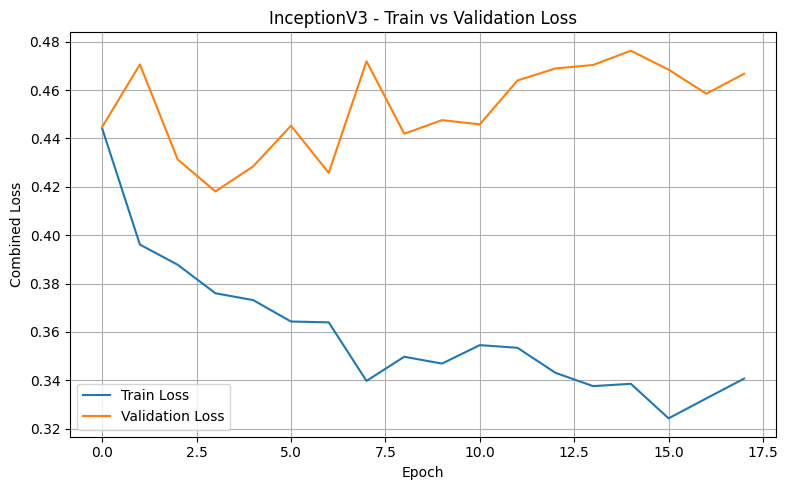

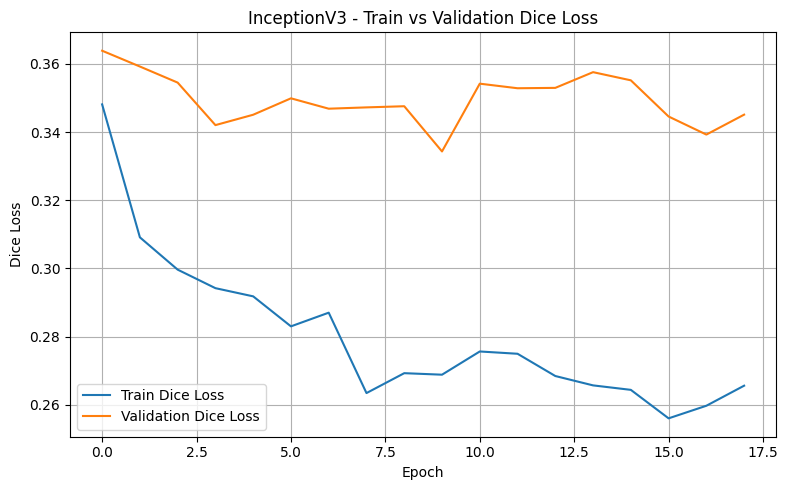

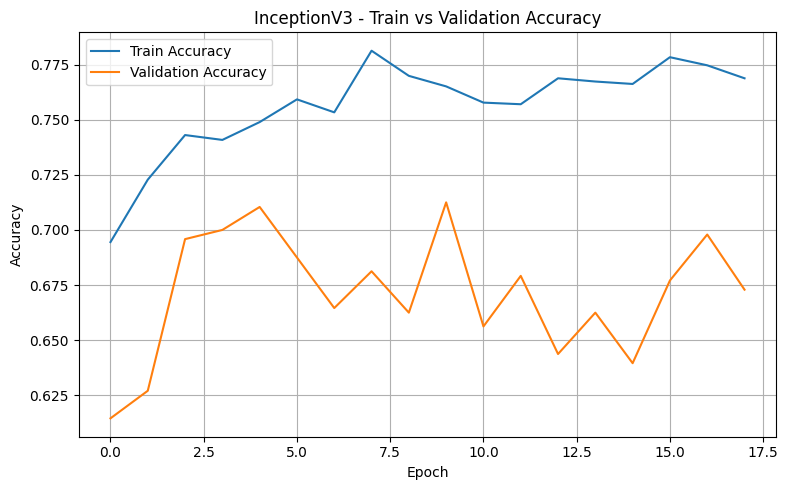


INCEPTIONV3 BASELINE RESULTS
Test Accuracy: 0.9176
Test Precision (Weighted): 0.9180
Test Recall (Weighted): 0.9176
Test F1-score (Weighted): 0.9152

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9153    0.9753    0.9443      1052
  Appears normal     0.9251    0.7716    0.8414       416

        accuracy                         0.9176      1468
       macro avg     0.9202    0.8735    0.8929      1468
    weighted avg     0.9180    0.9176    0.9152      1468



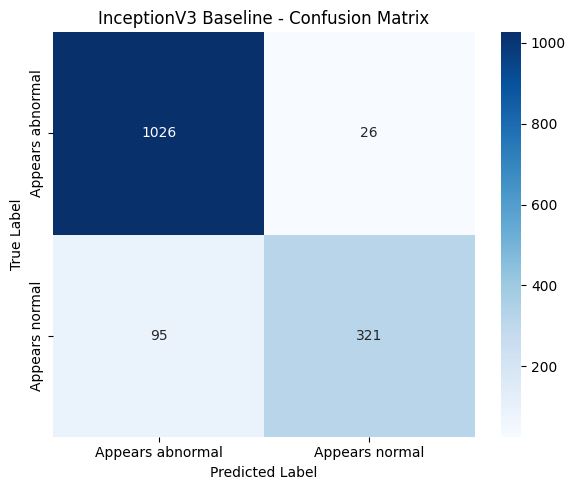

In [15]:
# ============================================================
# INCEPTIONV3 BASELINE - PCOS CLASSIFICATION
# 85% TRAIN / 15% VALIDATION
# ============================================================

import os
import copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torchvision import datasets, transforms
from torchvision.models import inception_v3, Inception_V3_Weights

from torch.utils.data import (
    DataLoader,
    random_split,
    WeightedRandomSampler
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ============================================================
# PATHS
# ============================================================

train_dir = "/kaggle/working/PCOSGen-train/train"
test_dir = "/kaggle/working/PCOSGen-train/test"

# ============================================================
# PARAMETERS
# ============================================================

IMG_SIZE = 299
BATCH_SIZE = 32
NUM_EPOCHS = 50
LEARNING_RATE = 0.0001
PATIENCE = 8

# ============================================================
# TRANSFORMS
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# DATASETS
# ============================================================

full_train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

class_names = full_train_dataset.classes
num_classes = len(class_names)

print("\nClasses:", class_names)
print("Number of classes:", num_classes)
print("Total training images:", len(full_train_dataset))
print("Test images:", len(test_dataset))

# ============================================================
# 85% TRAIN / 15% VALIDATION
# ============================================================

train_size = int(
    0.85 * len(full_train_dataset)
)

val_size = (
    len(full_train_dataset) -
    train_size
)

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=generator
)

# ------------------------------------------------------------
# IMPORTANT:
# Validation should NOT use augmentation
# ------------------------------------------------------------

val_dataset.dataset = copy.deepcopy(
    full_train_dataset
)

val_dataset.dataset.transform = val_test_transform

print("\nTraining images:", len(train_dataset))
print("Validation images:", len(val_dataset))

# ============================================================
# WEIGHTED RANDOM SAMPLER
# ============================================================

train_targets = [
    full_train_dataset.targets[i]
    for i in train_dataset.indices
]

class_counts = np.bincount(
    train_targets
)

print("\nTraining class counts:", class_counts)

class_weights = 1.0 / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]

sample_weights = torch.DoubleTensor(
    sample_weights
)

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# ============================================================
# DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ============================================================
# INCEPTIONV3 MODEL
# ============================================================

weights = Inception_V3_Weights.IMAGENET1K_V1

inception = inception_v3(
    weights=weights,
    aux_logits=True
)

# Replace final classifier
inception.fc = nn.Linear(
    inception.fc.in_features,
    num_classes
)

inception = inception.to(device)

print("\nInceptionV3 loaded successfully.")

print(
    "Number of parameters:",
    sum(
        p.numel()
        for p in inception.parameters()
    )
)

# ============================================================
# DICE LOSS
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):

        super().__init__()

        self.smooth = smooth

    def forward(self, inputs, targets):

        probs = torch.softmax(
            inputs,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=inputs.size(1)
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        denominator = (
            probs.sum(dim=0)
            +
            targets_one_hot.sum(dim=0)
        )

        dice = (
            2.0 * intersection
            +
            self.smooth
        ) / (
            denominator
            +
            self.smooth
        )

        return 1 - dice.mean()

# ============================================================
# LOSS FUNCTIONS
# ============================================================

criterion_ce = nn.CrossEntropyLoss()

criterion_dice = DiceLoss()

def combined_loss(outputs, targets):

    ce_loss = criterion_ce(
        outputs,
        targets
    )

    dice_loss = criterion_dice(
        outputs,
        targets
    )

    total_loss = (
        0.5 * ce_loss
        +
        0.5 * dice_loss
    )

    return (
        total_loss,
        ce_loss,
        dice_loss
    )

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    inception.parameters(),
    lr=LEARNING_RATE
)

# ============================================================
# TRAINING HISTORY
# ============================================================

train_losses = []
val_losses = []

train_dice_losses = []
val_dice_losses = []

train_accuracies = []
val_accuracies = []

# ============================================================
# EARLY STOPPING VARIABLES
# ============================================================

best_val_accuracy = 0.0

best_model_weights = copy.deepcopy(
    inception.state_dict()
)

patience_counter = 0

# ============================================================
# TRAINING
# ============================================================

print("\nStarting InceptionV3 training...\n")

for epoch in range(NUM_EPOCHS):

    # ========================================================
    # TRAIN
    # ========================================================

    inception.train()

    running_loss = 0.0
    running_dice_loss = 0.0

    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # ----------------------------------------------------
        # InceptionV3 returns InceptionOutputs when aux_logits
        # is enabled.
        # We use the main output for our loss.
        # ----------------------------------------------------

        outputs = inception(images)

        if hasattr(outputs, "logits"):

            outputs = outputs.logits

        elif isinstance(outputs, tuple):

            outputs = outputs[0]

        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        total_loss, ce_loss, dice_loss = combined_loss(
            outputs,
            labels
        )

        total_loss.backward()

        optimizer.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        running_loss += (
            total_loss.item()
            *
            images.size(0)
        )

        running_dice_loss += (
            dice_loss.item()
            *
            images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    epoch_train_loss = (
        running_loss
        /
        len(train_loader.dataset)
    )

    epoch_train_dice = (
        running_dice_loss
        /
        len(train_loader.dataset)
    )

    epoch_train_accuracy = (
        correct / total
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    inception.eval()

    val_running_loss = 0.0
    val_running_dice = 0.0

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = inception(images)

            if hasattr(outputs, "logits"):

                outputs = outputs.logits

            elif isinstance(outputs, tuple):

                outputs = outputs[0]

            # ------------------------------------------------
            # Validation loss
            # ------------------------------------------------

            total_loss, ce_loss, dice_loss = combined_loss(
                outputs,
                labels
            )

            val_running_loss += (
                total_loss.item()
                *
                images.size(0)
            )

            val_running_dice += (
                dice_loss.item()
                *
                images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            val_total += labels.size(0)

            val_correct += (
                predicted == labels
            ).sum().item()

    epoch_val_loss = (
        val_running_loss
        /
        len(val_loader.dataset)
    )

    epoch_val_dice = (
        val_running_dice
        /
        len(val_loader.dataset)
    )

    epoch_val_accuracy = (
        val_correct
        /
        val_total
    )

    # ========================================================
    # STORE HISTORY
    # ========================================================

    train_losses.append(
        epoch_train_loss
    )

    val_losses.append(
        epoch_val_loss
    )

    train_dice_losses.append(
        epoch_train_dice
    )

    val_dice_losses.append(
        epoch_val_dice
    )

    train_accuracies.append(
        epoch_train_accuracy
    )

    val_accuracies.append(
        epoch_val_accuracy
    )

    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Train Acc: {epoch_train_accuracy:.4f} | "
        f"Val Acc: {epoch_val_accuracy:.4f}"
    )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = (
            epoch_val_accuracy
        )

        best_model_weights = copy.deepcopy(
            inception.state_dict()
        )

        patience_counter = 0

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:

            print(
                "\nEarly stopping triggered."
            )

            break

# ============================================================
# LOAD BEST MODEL
# ============================================================

inception.load_state_dict(
    best_model_weights
)

inception.eval()

best_inception_model = inception

print(
    "\nBest Validation Accuracy:",
    f"{best_val_accuracy:.4f}"
)

# ============================================================
# SAVE BEST MODEL
# ============================================================

torch.save(
    inception.state_dict(),
    "/kaggle/working/InceptionV3_Baseline.pkl"
)

print(
    "Best InceptionV3 model saved successfully."
)

# ============================================================
# GRAPH 1
# TRAIN VS VALIDATION COMBINED LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Combined Loss")

plt.title(
    "InceptionV3 - Train vs Validation Loss"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# GRAPH 2
# TRAIN VS VALIDATION DICE LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    train_dice_losses,
    label="Train Dice Loss"
)

plt.plot(
    val_dice_losses,
    label="Validation Dice Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Loss")

plt.title(
    "InceptionV3 - Train vs Validation Dice Loss"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# GRAPH 3
# TRAIN VS VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    label="Train Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "InceptionV3 - Train vs Validation Accuracy"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# TEST EVALUATION
# ============================================================

all_test_labels = []
all_test_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = inception(images)

        if hasattr(outputs, "logits"):

            outputs = outputs.logits

        elif isinstance(outputs, tuple):

            outputs = outputs[0]

        _, predictions = torch.max(
            outputs,
            1
        )

        all_test_labels.extend(
            labels.numpy()
        )

        all_test_predictions.extend(
            predictions.cpu().numpy()
        )

# ============================================================
# BASELINE METRICS
# ============================================================

baseline_accuracy = accuracy_score(
    all_test_labels,
    all_test_predictions
)

baseline_precision = precision_score(
    all_test_labels,
    all_test_predictions,
    average="weighted",
    zero_division=0
)

baseline_recall = recall_score(
    all_test_labels,
    all_test_predictions,
    average="weighted",
    zero_division=0
)

baseline_f1 = f1_score(
    all_test_labels,
    all_test_predictions,
    average="weighted",
    zero_division=0
)

# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 55)

print(
    "INCEPTIONV3 BASELINE RESULTS"
)

print("=" * 55)

print(
    f"Test Accuracy: "
    f"{baseline_accuracy:.4f}"
)

print(
    f"Test Precision (Weighted): "
    f"{baseline_precision:.4f}"
)

print(
    f"Test Recall (Weighted): "
    f"{baseline_recall:.4f}"
)

print(
    f"Test F1-score (Weighted): "
    f"{baseline_f1:.4f}"
)

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print(
    "\nClassification Report:"
)

print(
    classification_report(
        all_test_labels,
        all_test_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_test_labels,
    all_test_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "InceptionV3 Baseline - Confusion Matrix"
)

plt.xlabel("Predicted Label")

plt.ylabel("True Label")

plt.tight_layout()

plt.show()

In [18]:
# ============================================================
# INCEPTIONV3 FEATURE EXTRACTION
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F

# ============================================================
# FEATURE EXTRACTION
# ============================================================

def extract_inception_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # ------------------------------------------------
            # InceptionV3 convolutional feature extractor
            # ------------------------------------------------

            x = model.Conv2d_1a_3x3(images)
            x = model.Conv2d_2a_3x3(x)
            x = model.Conv2d_2b_3x3(x)

            x = F.max_pool2d(
                x,
                kernel_size=3,
                stride=2
            )

            x = model.Conv2d_3b_1x1(x)
            x = model.Conv2d_4a_3x3(x)

            x = F.max_pool2d(
                x,
                kernel_size=3,
                stride=2
            )

            x = model.Mixed_5b(x)
            x = model.Mixed_5c(x)
            x = model.Mixed_5d(x)

            x = model.Mixed_6a(x)
            x = model.Mixed_6b(x)
            x = model.Mixed_6c(x)
            x = model.Mixed_6d(x)
            x = model.Mixed_6e(x)

            x = model.Mixed_7a(x)
            x = model.Mixed_7b(x)
            x = model.Mixed_7c(x)

            # ------------------------------------------------
            # Global Average Pooling
            # ------------------------------------------------

            x = model.avgpool(x)

            x = torch.flatten(
                x,
                1
            )

            features.append(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.cpu().numpy()
            )

    return (
        np.concatenate(features),
        np.array(labels_list)
    )


# ============================================================
# USE THE BEST INCEPTIONV3 MODEL
# ============================================================

best_inception_model = inception

best_inception_model.eval()

# ============================================================
# EXTRACT FEATURES
# ============================================================

print("Extracting InceptionV3 features...")

train_features, train_labels = extract_inception_features(
    best_inception_model,
    train_loader
)

val_features, val_labels = extract_inception_features(
    best_inception_model,
    val_loader
)

test_features, test_labels = extract_inception_features(
    best_inception_model,
    test_loader
)

# ============================================================
# FEATURE SHAPES
# ============================================================

print("\nFeature extraction completed.")

print(
    "Train features:",
    train_features.shape
)

print(
    "Validation features:",
    val_features.shape
)

print(
    "Test features:",
    test_features.shape
)

Extracting InceptionV3 features...

Feature extraction completed.
Train features: (2720, 2048)
Validation features: (480, 2048)
Test features: (1468, 2048)


# Random Forest

Train features: (2720, 2048)
Validation features: (480, 2048)
Test features: (1468, 2048)

RANDOM FOREST - INCEPTIONV3
Random Forest Validation Accuracy: 0.6646
Random Forest Test Accuracy: 0.8774
Random Forest Test Precision (Weighted): 0.8802
Random Forest Test Recall (Weighted): 0.8774
Random Forest Test F1-score (Weighted): 0.8785

Random Forest Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9250    0.9021    0.9134      1052
  Appears normal     0.7670    0.8149    0.7902       416

        accuracy                         0.8774      1468
       macro avg     0.8460    0.8585    0.8518      1468
    weighted avg     0.8802    0.8774    0.8785      1468



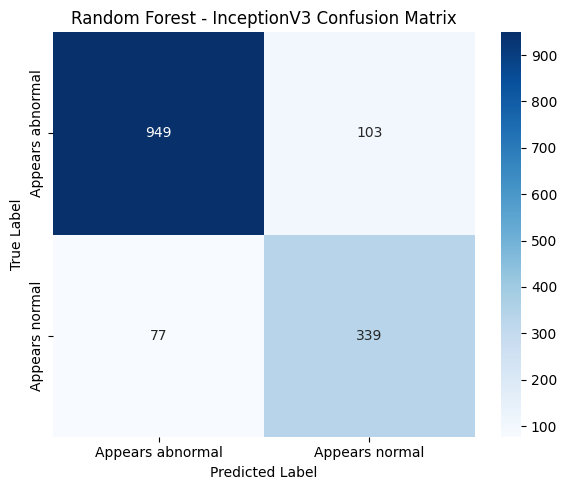


---------------- Random Forest ----------------
Random Forest Validation Accuracy: 0.6646
Random Forest Test Accuracy: 0.8774
Random Forest Test Precision: 0.8802
Random Forest Test Recall: 0.8774
Random Forest Test F1-score: 0.8785


In [25]:
# ============================================================
# RANDOM FOREST - INCEPTIONV3 FEATURES
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# CHECK FEATURES
# ============================================================

print("Train features:", train_features.shape)
print("Validation features:", val_features.shape)
print("Test features:", test_features.shape)

# ============================================================
# RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(
    train_features,
    train_labels
)

# ============================================================
# VALIDATION PREDICTION
# ============================================================

val_pred_rf = rf_model.predict(
    val_features
)

rf_val_accuracy = accuracy_score(
    val_labels,
    val_pred_rf
)

# ============================================================
# TEST PREDICTION
# ============================================================

test_pred_rf = rf_model.predict(
    test_features
)

rf_test_accuracy = accuracy_score(
    test_labels,
    test_pred_rf
)

rf_test_precision = precision_score(
    test_labels,
    test_pred_rf,
    average="weighted",
    zero_division=0
)

rf_test_recall = recall_score(
    test_labels,
    test_pred_rf,
    average="weighted",
    zero_division=0
)

rf_test_f1 = f1_score(
    test_labels,
    test_pred_rf,
    average="weighted",
    zero_division=0
)

# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 50)
print("RANDOM FOREST - INCEPTIONV3")
print("=" * 50)

print(
    f"Random Forest Validation Accuracy: "
    f"{rf_val_accuracy:.4f}"
)

print(
    f"Random Forest Test Accuracy: "
    f"{rf_test_accuracy:.4f}"
)

print(
    f"Random Forest Test Precision (Weighted): "
    f"{rf_test_precision:.4f}"
)

print(
    f"Random Forest Test Recall (Weighted): "
    f"{rf_test_recall:.4f}"
)

print(
    f"Random Forest Test F1-score (Weighted): "
    f"{rf_test_f1:.4f}"
)

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nRandom Forest Classification Report:")

print(
    classification_report(
        test_labels,
        test_pred_rf,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm_rf = confusion_matrix(
    test_labels,
    test_pred_rf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Random Forest - InceptionV3 Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n---------------- Random Forest ----------------")

print(
    f"Random Forest Validation Accuracy: "
    f"{rf_val_accuracy:.4f}"
)

print(
    f"Random Forest Test Accuracy: "
    f"{rf_test_accuracy:.4f}"
)

print(
    f"Random Forest Test Precision: "
    f"{rf_test_precision:.4f}"
)

print(
    f"Random Forest Test Recall: "
    f"{rf_test_recall:.4f}"
)

print(
    f"Random Forest Test F1-score: "
    f"{rf_test_f1:.4f}"
)

# KNN


---------------- KNN ----------------
KNN Validation Accuracy: 0.7042
KNN Test Accuracy: 0.8495
KNN Test Precision: 0.8537
KNN Test Recall: 0.8495
KNN Test F1-score: 0.8511

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9078    0.8793    0.8933      1052
  Appears normal     0.7171    0.7740    0.7445       416

        accuracy                         0.8495      1468
       macro avg     0.8125    0.8267    0.8189      1468
    weighted avg     0.8537    0.8495    0.8511      1468



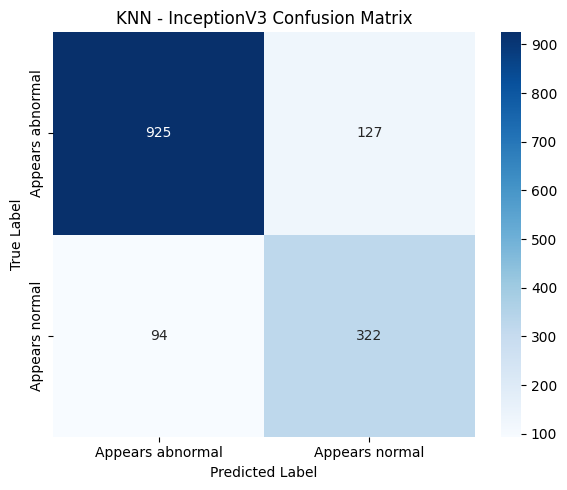

In [20]:
# ============================================================
# KNN - INCEPTIONV3 FEATURES
# ============================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    train_features,
    train_labels
)

# Validation
val_pred_knn = knn_model.predict(
    val_features
)

knn_val_accuracy = accuracy_score(
    val_labels,
    val_pred_knn
)

# Test
test_pred_knn = knn_model.predict(
    test_features
)

knn_test_accuracy = accuracy_score(
    test_labels,
    test_pred_knn
)

knn_test_precision = precision_score(
    test_labels,
    test_pred_knn,
    average="weighted",
    zero_division=0
)

knn_test_recall = recall_score(
    test_labels,
    test_pred_knn,
    average="weighted",
    zero_division=0
)

knn_test_f1 = f1_score(
    test_labels,
    test_pred_knn,
    average="weighted",
    zero_division=0
)

print("\n---------------- KNN ----------------")

print(
    f"KNN Validation Accuracy: "
    f"{knn_val_accuracy:.4f}"
)

print(
    f"KNN Test Accuracy: "
    f"{knn_test_accuracy:.4f}"
)

print(
    f"KNN Test Precision: "
    f"{knn_test_precision:.4f}"
)

print(
    f"KNN Test Recall: "
    f"{knn_test_recall:.4f}"
)

print(
    f"KNN Test F1-score: "
    f"{knn_test_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        test_labels,
        test_pred_knn,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm_knn = confusion_matrix(
    test_labels,
    test_pred_knn
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "KNN - InceptionV3 Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

# Naive Bayes


---------------- Naive Bayes ----------------
Naive Bayes Validation Accuracy: 0.5667
Naive Bayes Test Accuracy: 0.8338
Naive Bayes Test Precision: 0.8640
Naive Bayes Test Recall: 0.8338
Naive Bayes Test F1-score: 0.8401

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9479    0.8127    0.8751      1052
  Appears normal     0.6519    0.8870    0.7515       416

        accuracy                         0.8338      1468
       macro avg     0.7999    0.8499    0.8133      1468
    weighted avg     0.8640    0.8338    0.8401      1468



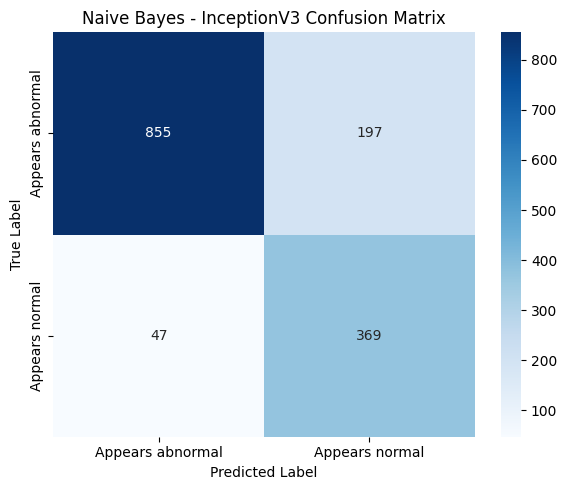

In [21]:
# ============================================================
# NAIVE BAYES - INCEPTIONV3 FEATURES
# ============================================================

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

nb_model = GaussianNB()

nb_model.fit(
    train_features,
    train_labels
)

# Validation
val_pred_nb = nb_model.predict(
    val_features
)

nb_val_accuracy = accuracy_score(
    val_labels,
    val_pred_nb
)

# Test
test_pred_nb = nb_model.predict(
    test_features
)

nb_test_accuracy = accuracy_score(
    test_labels,
    test_pred_nb
)

nb_test_precision = precision_score(
    test_labels,
    test_pred_nb,
    average="weighted",
    zero_division=0
)

nb_test_recall = recall_score(
    test_labels,
    test_pred_nb,
    average="weighted",
    zero_division=0
)

nb_test_f1 = f1_score(
    test_labels,
    test_pred_nb,
    average="weighted",
    zero_division=0
)

print("\n---------------- Naive Bayes ----------------")

print(
    f"Naive Bayes Validation Accuracy: "
    f"{nb_val_accuracy:.4f}"
)

print(
    f"Naive Bayes Test Accuracy: "
    f"{nb_test_accuracy:.4f}"
)

print(
    f"Naive Bayes Test Precision: "
    f"{nb_test_precision:.4f}"
)

print(
    f"Naive Bayes Test Recall: "
    f"{nb_test_recall:.4f}"
)

print(
    f"Naive Bayes Test F1-score: "
    f"{nb_test_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        test_labels,
        test_pred_nb,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm_nb = confusion_matrix(
    test_labels,
    test_pred_nb
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Naive Bayes - InceptionV3 Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

# Adaboost


---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6375
AdaBoost Test Accuracy: 0.8706
AdaBoost Test Precision: 0.8737
AdaBoost Test Recall: 0.8706
AdaBoost Test F1-score: 0.8718

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9209    0.8964    0.9085      1052
  Appears normal     0.7545    0.8053    0.7791       416

        accuracy                         0.8706      1468
       macro avg     0.8377    0.8508    0.8438      1468
    weighted avg     0.8737    0.8706    0.8718      1468



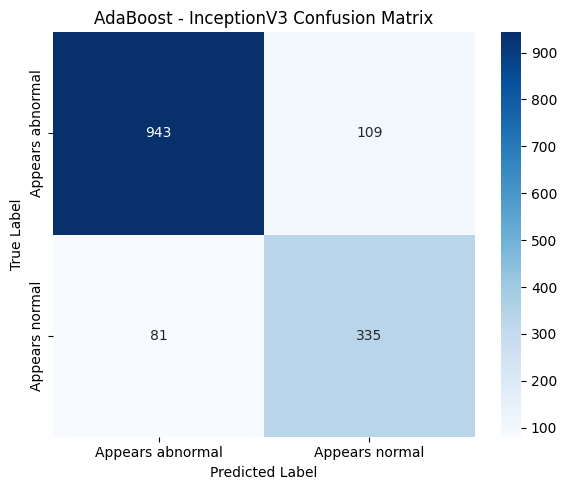

In [22]:
# ============================================================
# ADABOOST - INCEPTIONV3 FEATURES
# ============================================================

from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

adaboost_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

adaboost_model.fit(
    train_features,
    train_labels
)

# Validation
val_pred_ada = adaboost_model.predict(
    val_features
)

ada_val_accuracy = accuracy_score(
    val_labels,
    val_pred_ada
)

# Test
test_pred_ada = adaboost_model.predict(
    test_features
)

ada_test_accuracy = accuracy_score(
    test_labels,
    test_pred_ada
)

ada_test_precision = precision_score(
    test_labels,
    test_pred_ada,
    average="weighted",
    zero_division=0
)

ada_test_recall = recall_score(
    test_labels,
    test_pred_ada,
    average="weighted",
    zero_division=0
)

ada_test_f1 = f1_score(
    test_labels,
    test_pred_ada,
    average="weighted",
    zero_division=0
)

print("\n---------------- AdaBoost ----------------")

print(
    f"AdaBoost Validation Accuracy: "
    f"{ada_val_accuracy:.4f}"
)

print(
    f"AdaBoost Test Accuracy: "
    f"{ada_test_accuracy:.4f}"
)

print(
    f"AdaBoost Test Precision: "
    f"{ada_test_precision:.4f}"
)

print(
    f"AdaBoost Test Recall: "
    f"{ada_test_recall:.4f}"
)

print(
    f"AdaBoost Test F1-score: "
    f"{ada_test_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        test_labels,
        test_pred_ada,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm_ada = confusion_matrix(
    test_labels,
    test_pred_ada
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_ada,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "AdaBoost - InceptionV3 Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

# XGboost


---------------- XGBoost ----------------
XGBoost Validation Accuracy: 0.6792
XGBoost Test Accuracy: 0.8678
XGBoost Test Precision: 0.8682
XGBoost Test Recall: 0.8678
XGBoost Test F1-score: 0.8680

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9094    0.9059    0.9076      1052
  Appears normal     0.7643    0.7716    0.7679       416

        accuracy                         0.8678      1468
       macro avg     0.8368    0.8388    0.8378      1468
    weighted avg     0.8682    0.8678    0.8680      1468



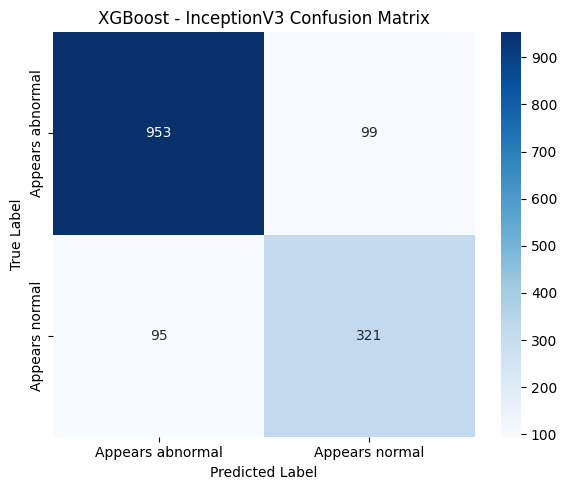

In [23]:
# ============================================================
# XGBOOST - INCEPTIONV3 FEATURES
# ============================================================

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    train_features,
    train_labels
)

# Validation
val_pred_xgb = xgb_model.predict(
    val_features
)

xgb_val_accuracy = accuracy_score(
    val_labels,
    val_pred_xgb
)

# Test
test_pred_xgb = xgb_model.predict(
    test_features
)

xgb_test_accuracy = accuracy_score(
    test_labels,
    test_pred_xgb
)

xgb_test_precision = precision_score(
    test_labels,
    test_pred_xgb,
    average="weighted",
    zero_division=0
)

xgb_test_recall = recall_score(
    test_labels,
    test_pred_xgb,
    average="weighted",
    zero_division=0
)

xgb_test_f1 = f1_score(
    test_labels,
    test_pred_xgb,
    average="weighted",
    zero_division=0
)

print("\n---------------- XGBoost ----------------")

print(
    f"XGBoost Validation Accuracy: "
    f"{xgb_val_accuracy:.4f}"
)

print(
    f"XGBoost Test Accuracy: "
    f"{xgb_test_accuracy:.4f}"
)

print(
    f"XGBoost Test Precision: "
    f"{xgb_test_precision:.4f}"
)

print(
    f"XGBoost Test Recall: "
    f"{xgb_test_recall:.4f}"
)

print(
    f"XGBoost Test F1-score: "
    f"{xgb_test_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        test_labels,
        test_pred_xgb,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm_xgb = confusion_matrix(
    test_labels,
    test_pred_xgb
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "XGBoost - InceptionV3 Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

# SVM


---------------- SVM ----------------
SVM Validation Accuracy: 0.6521
SVM Test Accuracy: 0.8924
SVM Test Precision: 0.8940
SVM Test Recall: 0.8924
SVM Test F1-score: 0.8930

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9323    0.9163    0.9243      1052
  Appears normal     0.7972    0.8317    0.8141       416

        accuracy                         0.8924      1468
       macro avg     0.8648    0.8740    0.8692      1468
    weighted avg     0.8940    0.8924    0.8930      1468



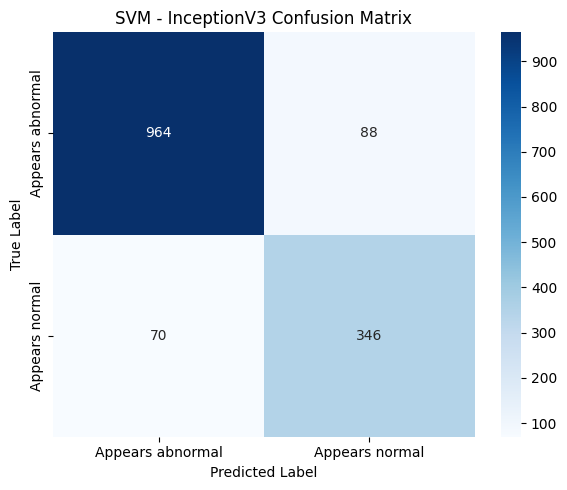

In [24]:
# ============================================================
# SVM - INCEPTIONV3 FEATURES
# ============================================================

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

svm_model.fit(
    train_features,
    train_labels
)

# Validation
val_pred_svm = svm_model.predict(
    val_features
)

svm_val_accuracy = accuracy_score(
    val_labels,
    val_pred_svm
)

# Test
test_pred_svm = svm_model.predict(
    test_features
)

svm_test_accuracy = accuracy_score(
    test_labels,
    test_pred_svm
)

svm_test_precision = precision_score(
    test_labels,
    test_pred_svm,
    average="weighted",
    zero_division=0
)

svm_test_recall = recall_score(
    test_labels,
    test_pred_svm,
    average="weighted",
    zero_division=0
)

svm_test_f1 = f1_score(
    test_labels,
    test_pred_svm,
    average="weighted",
    zero_division=0
)

print("\n---------------- SVM ----------------")

print(
    f"SVM Validation Accuracy: "
    f"{svm_val_accuracy:.4f}"
)

print(
    f"SVM Test Accuracy: "
    f"{svm_test_accuracy:.4f}"
)

print(
    f"SVM Test Precision: "
    f"{svm_test_precision:.4f}"
)

print(
    f"SVM Test Recall: "
    f"{svm_test_recall:.4f}"
)

print(
    f"SVM Test F1-score: "
    f"{svm_test_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        test_labels,
        test_pred_svm,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm_svm = confusion_matrix(
    test_labels,
    test_pred_svm
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "SVM - InceptionV3 Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()